# EEG background noise

Saina Nikmehr — CS 163 ABR Deconvolution

I use the EEG before each stimulus to look at three questions: how correlated neighboring samples are, what the correlation looks like over a longer window, and whether the amplitudes look Gaussian.

I start with five Experiment 2 recordings from OpenNeuro. The plots are calculated from the EEG files.

## 1. Load the recordings

`DATA_ROOT` should point to the folder containing `sub-exp221/eeg/`. The notebook normally runs on participants 221–225. Setting `MODE = "all"` uses every downloaded recording it can find.

In [6]:
from pathlib import Path
import gc
import re

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.signal import butter, resample_poly, sosfiltfilt
from scipy.stats import kurtosis, norm, probplot, skew
from IPython.display import display

# Settings to change when running on your computer.
DATA_ROOT = None        # Example: Path(r"C:\OpenNeuro\ds008065")
MODE = "all"           # "five" or "all"
MIN_RECORDINGS = 0     # Set to 30 for the 30+ analysis.
QQ_PARTICIPANT = "sub-exp221"

REPORT_PARTICIPANTS = [f"sub-exp22{i}" for i in range(1, 6)]
FS_ORIGINAL = 10_000
FS_ANALYSIS = 1_000
BASELINE_START_MS = -450
BASELINE_END_MS = -50
COVARIANCE_MS = 75

# Keep the amplitude convention from the original exploration.
# MNE returns EEG values in volts. The additional /100 was used in our
# previous notebooks; verify it from the recording metadata before
# interpreting any absolute voltage amplitudes as calibrated microvolts.
EEG_SCALE = 1e6 / 100.0

if DATA_ROOT is None:
    candidates = [Path.cwd(), *list(Path.cwd().parents)[:3]]
    DATA_ROOT = next(
        (folder for folder in candidates
         if any(folder.glob("sub-exp*/eeg/*_eeg.vhdr"))), None
    )
if DATA_ROOT is None:
    raise FileNotFoundError(
        "No EEG folders found. Set DATA_ROOT above to the folder containing sub-exp221/eeg/."
    )

DATA_ROOT = Path(DATA_ROOT)
OUTPUT_DIR = Path.cwd() / "noise_results"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Data directory:", DATA_ROOT)
print("Mode:", MODE)
print("Output directory:", OUTPUT_DIR)

Data directory: c:\Users\sniki\Downloads\Caltech\Third Year\Katie's ABR project\First Week Material
Mode: all
Output directory: c:\Users\sniki\Downloads\Caltech\Third Year\Katie's ABR project\First Week Material\analysis\noise_results


### Choose participants

I look for BrainVision recordings in each participant's `eeg` folder. The experiment number stays in the results so recordings from different experiments are not mixed up.

In [7]:
def experiment_number(participant):
    match = re.fullmatch(r"sub-exp([123])\d+", participant)
    if match is None:
        raise ValueError(f"Unexpected participant folder: {participant}")
    return int(match.group(1))


def discover_participants(root):
    names = {header.parent.parent.name
             for header in root.glob("sub-exp*/eeg/*_eeg.vhdr")}
    names = [name for name in names
             if re.fullmatch(r"sub-exp[123]\d+", name)]
    return sorted(names, key=lambda name: (experiment_number(name), int(name[7:])))


if MODE == "five":
    participants = REPORT_PARTICIPANTS.copy()
elif MODE == "all":
    participants = discover_participants(DATA_ROOT)
else:
    raise ValueError("MODE must be 'five' or 'all'")

print(f"Selected {len(participants)} participant folders:")
print(", ".join(participants) if participants else "None")
if not participants:
    raise FileNotFoundError("No participant EEG headers were found in DATA_ROOT.")

Selected 25 participant folders:
sub-exp221, sub-exp222, sub-exp223, sub-exp224, sub-exp225, sub-exp226, sub-exp227, sub-exp228, sub-exp229, sub-exp230, sub-exp301, sub-exp302, sub-exp303, sub-exp304, sub-exp305, sub-exp306, sub-exp307, sub-exp308, sub-exp309, sub-exp310, sub-exp311, sub-exp312, sub-exp313, sub-exp314, sub-exp315


## 2. Extract pre-stimulus EEG

For every stimulus onset, I take the **−450 to −50 ms** interval from channel `FCzA1`. I read a slightly longer segment first so the filtering does not act right at the edges of the window.

I compare the raw signal with a version filtered from 30–2000 Hz, then downsample both to 1 kHz. After downsampling, only frequencies below 500 Hz remain. These windows give a baseline noise estimate, although they could still contain activity left over from an earlier stimulus.

In [8]:
def extract_baselines(participant, keep_full_rate=False):
    eeg_dir = DATA_ROOT / participant / "eeg"
    headers = sorted(eeg_dir.glob("*_eeg.vhdr"))
    if not headers:
        raise FileNotFoundError(f"No .vhdr file in {eeg_dir}")

    raw_windows, filtered_windows, full_rate_windows = [], [], []
    bandpass = butter(1, [30, 2000], fs=FS_ORIGINAL,
                      btype="bandpass", output="sos")

    for header in headers:
        events_file = header.with_name(header.name.replace("_eeg.vhdr", "_events.tsv"))
        if not events_file.is_file():
            raise FileNotFoundError(f"Missing events table for {header.name}")
        events = pd.read_csv(events_file, sep="\t")
        required = {"trial_type", "sample_corrected"}
        if not required.issubset(events.columns):
            raise ValueError(f"Missing event columns in {events_file.name}: {required - set(events.columns)}")
        onsets = pd.to_numeric(
            events.loc[events["trial_type"].eq("stimulus_start"), "sample_corrected"],
            errors="coerce"
        ).dropna().round().astype(int).unique()

        raw = mne.io.read_raw_brainvision(str(header), preload=False, verbose="ERROR")
        try:
            if int(round(raw.info["sfreq"])) != FS_ORIGINAL:
                raise ValueError(f"Expected {FS_ORIGINAL} Hz for {header.name}")
            if "FCzA1" not in raw.ch_names:
                raise ValueError(f"FCzA1 channel not found in {header.name}")

            for onset in sorted(onsets):
                start = onset - 7500     # -750 ms at 10 kHz
                stop = onset - 100       # -10 ms at 10 kHz
                if start < 0 or stop > raw.n_times:
                    continue

                segment = raw.get_data(picks=["FCzA1"], start=start, stop=stop)[0]
                segment = segment * EEG_SCALE
                filtered = sosfiltfilt(bandpass, segment)

                # Relative to -750 ms, -450 ms starts at sample 3000.
                # -50 ms is sample 7000 (exclusive).
                raw_window = segment[3000:7000]
                filtered_window = filtered[3000:7000]
                raw_windows.append(resample_poly(raw_window, 1, 10))
                filtered_windows.append(resample_poly(filtered_window, 1, 10))
                if keep_full_rate:
                    full_rate_windows.append(raw_window)
        finally:
            raw.close()

    if len(raw_windows) < 160:
        raise ValueError(f"Only {len(raw_windows)} usable baseline windows; need at least 160")

    raw_data = np.stack(raw_windows)
    filtered_data = np.stack(filtered_windows)
    # Remove the constant offset separately from each 400-ms window.
    raw_data -= raw_data.mean(axis=1, keepdims=True)
    filtered_data -= filtered_data.mean(axis=1, keepdims=True)

    full_rate = None
    if keep_full_rate:
        full_rate = np.stack(full_rate_windows)
        full_rate -= full_rate.mean(axis=1, keepdims=True)
    return raw_data, filtered_data, full_rate

## 3. Measure temporal correlation

Each row of `windows` is one 400-ms baseline, and each column is a time point. I split the windows into alternating groups: one for the **1-ms correlation** and the other for the correlation matrices.

For neighboring samples, I subtract the across-trial mean at each time point and calculate

$$
\widehat\rho_1 =
\frac{\sum_{i,t} (x_{i,t}-\bar x_t)(x_{i,t+1}-\bar x_{t+1})}
{\sum_{i,t}(x_{i,t}-\bar x_t)^2}.
$$

For the heatmaps, I calculate the sample covariance between time points within the first 75 ms, then normalize it to a correlation matrix. This compares **time points**, not pairs of participants or trials.

$$
\widehat\Sigma = \frac{1}{M-1}\sum_{i=1}^M
(\mathbf{x}_i-\bar{\mathbf{x}})(\mathbf{x}_i-\bar{\mathbf{x}})^\top,
\qquad
\widehat R_{ab}=\frac{\widehat\Sigma_{ab}}
{\sqrt{\widehat\Sigma_{aa}\widehat\Sigma_{bb}}}.
$$

The matrices compare **time positions within a window**, with covariance estimated across repeated windows. They are *not* trial-by-trial correlation matrices.

In [9]:
def one_ms_correlation(windows):
    train = windows[::2]
    centered = train - train.mean(axis=0, keepdims=True)
    before, after = centered[:, :-1], centered[:, 1:]
    denominator = np.sum(before ** 2)
    if denominator <= 0:
        raise ValueError("Lag-one correlation is undefined for constant windows")
    return float(np.sum(before * after) / denominator)


def correlation_matrix(windows):
    # Use windows not included in the lag-one estimate.
    test = windows[1::2, :COVARIANCE_MS]
    sample_covariance = np.cov(test, rowvar=False, ddof=1)
    standard_deviations = np.sqrt(np.diag(sample_covariance))
    if np.any(standard_deviations <= 0):
        raise ValueError("Correlation undefined at a zero-variance time position")
    return sample_covariance / np.outer(standard_deviations, standard_deviations)


## 4. Run the analysis

For each recording, I save the 1-ms correlation before and after filtering, along with its 75-ms correlation matrix. The EEG windows can be discarded once these summaries are computed.

In [10]:
summary_rows = []
matrices = {}
failures = []
qq_windows = None

for participant in participants:
    try:
        raw_windows, filtered_windows, full_rate_windows = extract_baselines(
            participant, keep_full_rate=(participant == QQ_PARTICIPANT)
        )
        summary_rows.append({
            "participant": participant,
            "experiment": experiment_number(participant),
            "windows": len(raw_windows),
            "raw_rho": one_ms_correlation(raw_windows),
            "filtered_rho": one_ms_correlation(filtered_windows),
        })
        matrices[participant] = correlation_matrix(filtered_windows)
        if full_rate_windows is not None:
            qq_windows = full_rate_windows
        print(f"{participant}: {len(raw_windows)} baselines analyzed")
    except (FileNotFoundError, ValueError, OSError, RuntimeError, KeyError) as error:
        failures.append({"participant": participant, "reason": str(error)})
        print(f"SKIPPED {participant}: {error}")
    gc.collect()

summary = pd.DataFrame(summary_rows)
if summary.empty:
    raise RuntimeError("No recordings were successfully analyzed. Check DATA_ROOT and the EEG/event files.")

summary.to_csv(OUTPUT_DIR / "noise_summary.csv", index=False)
print(f"\nSuccessful recordings: {len(summary)} / {len(participants)} selected")
if MIN_RECORDINGS and len(summary) < MIN_RECORDINGS:
    print(f"WARNING: fewer than {MIN_RECORDINGS} successful recordings."
          " Do not describe this as a 30+ recording analysis.")

display(summary.round(4))
if failures:
    print("Unsuccessful recordings:")
    display(pd.DataFrame(failures))
    pd.DataFrame(failures).to_csv(OUTPUT_DIR / "skipped_recordings.csv", index=False)

sub-exp221: 382 baselines analyzed
sub-exp222: 839 baselines analyzed
sub-exp223: 839 baselines analyzed
sub-exp224: 839 baselines analyzed
sub-exp225: 856 baselines analyzed
sub-exp226: 840 baselines analyzed
sub-exp227: 837 baselines analyzed
sub-exp228: 840 baselines analyzed
sub-exp229: 840 baselines analyzed
sub-exp230: 840 baselines analyzed
sub-exp301: 628 baselines analyzed
sub-exp302: 630 baselines analyzed
sub-exp303: 634 baselines analyzed
sub-exp304: 630 baselines analyzed
sub-exp305: 630 baselines analyzed
sub-exp306: 630 baselines analyzed
sub-exp307: 628 baselines analyzed
sub-exp308: 630 baselines analyzed
sub-exp309: 630 baselines analyzed
sub-exp310: 630 baselines analyzed
sub-exp311: 630 baselines analyzed
sub-exp312: 630 baselines analyzed
sub-exp313: 630 baselines analyzed
sub-exp314: 630 baselines analyzed
sub-exp315: 630 baselines analyzed

Successful recordings: 25 / 25 selected


,participant,experiment,windows,raw_rho,filtered_rho
0,sub-exp221,2,382,0.9922,0.7674
1,sub-exp222,2,839,0.9187,0.8628
2,sub-exp223,2,839,0.9902,0.5472
3,sub-exp224,2,839,0.9361,0.4058
4,sub-exp225,2,856,0.9213,0.4705
5,sub-exp226,2,840,0.9293,0.5035
6,sub-exp227,2,837,0.9256,0.5004
7,sub-exp228,2,840,0.9630,0.5728
8,sub-exp229,2,840,0.9229,0.5507
9,sub-exp230,2,840,0.9919,0.6393


## 5. Correlation at a 1-ms lag

This compares consecutive samples in the raw and filtered baseline recordings. A value close to zero would mean little dependence at this lag.

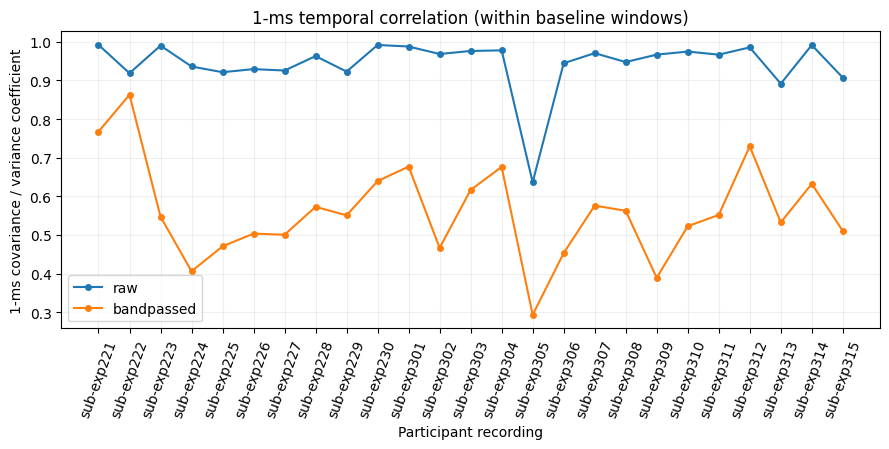

Number of successful recordings by experiment:


,recordings
experiment,
2,10
3,15


In [11]:
x = np.arange(len(summary))
fig, ax = plt.subplots(figsize=(max(8, 0.36 * len(summary)), 4.6))
ax.plot(x, summary["raw_rho"], "o-", label="raw", markersize=4)
ax.plot(x, summary["filtered_rho"], "o-", label="bandpassed", markersize=4)
ax.set_xticks(x)
ax.set_xticklabels(summary["participant"], rotation=70 if len(summary) > 10 else 20)
ax.set_xlabel("Participant recording")
ax.set_ylabel("1-ms covariance / variance coefficient")
ax.set_title("1-ms temporal correlation (within baseline windows)")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure3_temporal_correlation.png", dpi=180)
plt.show()

print("Number of successful recordings by experiment:")
display(summary.groupby("experiment").size().rename("recordings").to_frame())

## 6. Correlation across 75 ms

Each heatmap shows how EEG at one time point is correlated with EEG at another, across baseline windows. The diagonal is 1; the off-diagonal pattern is what tells us about temporal structure.

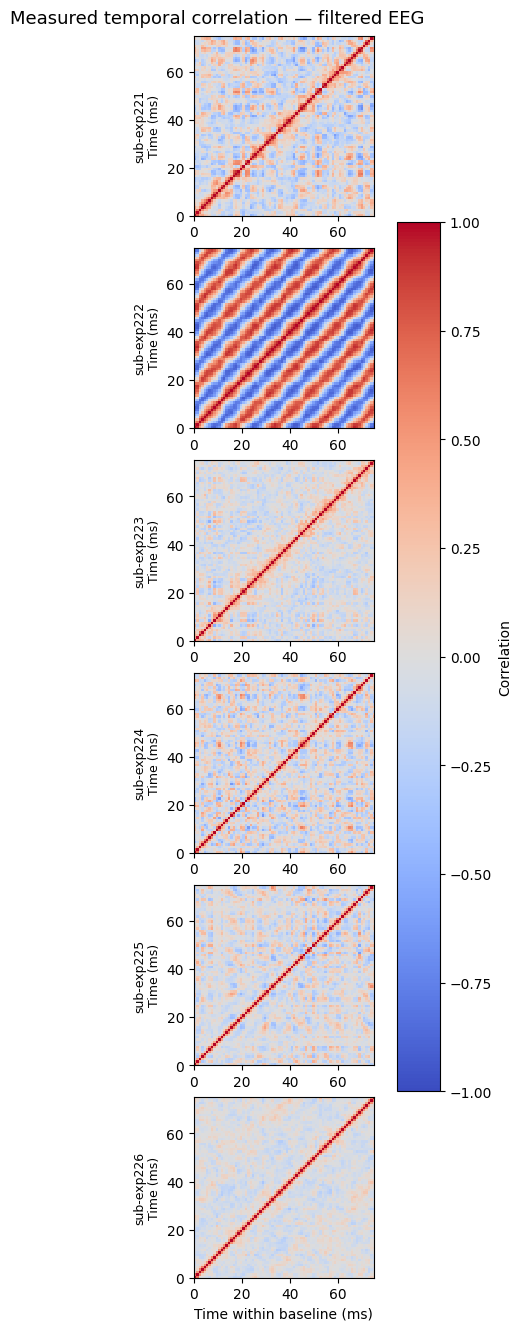

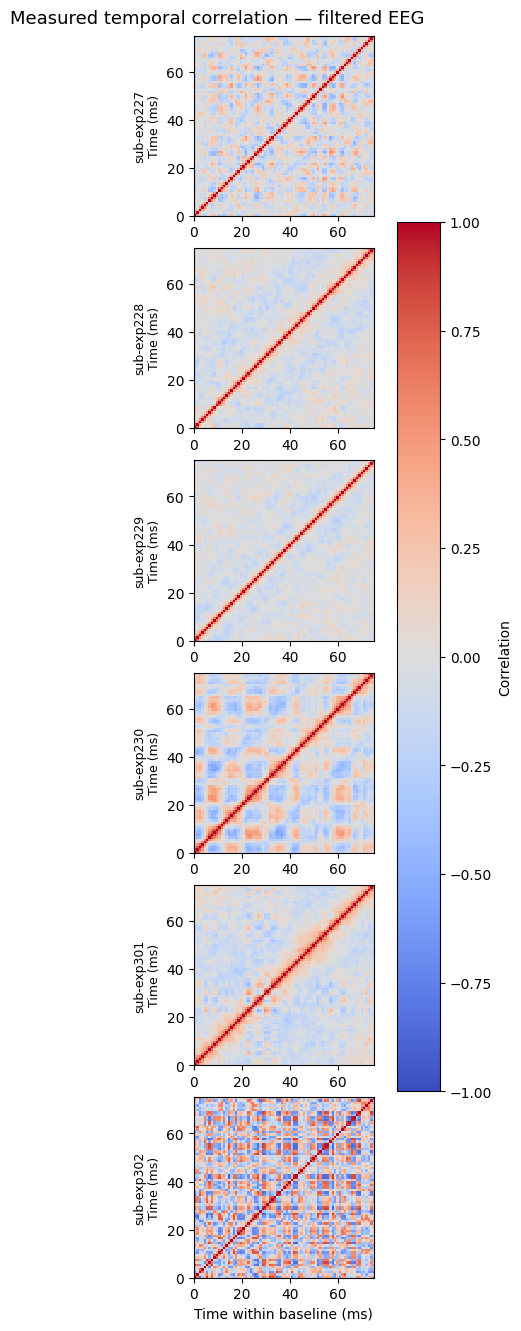

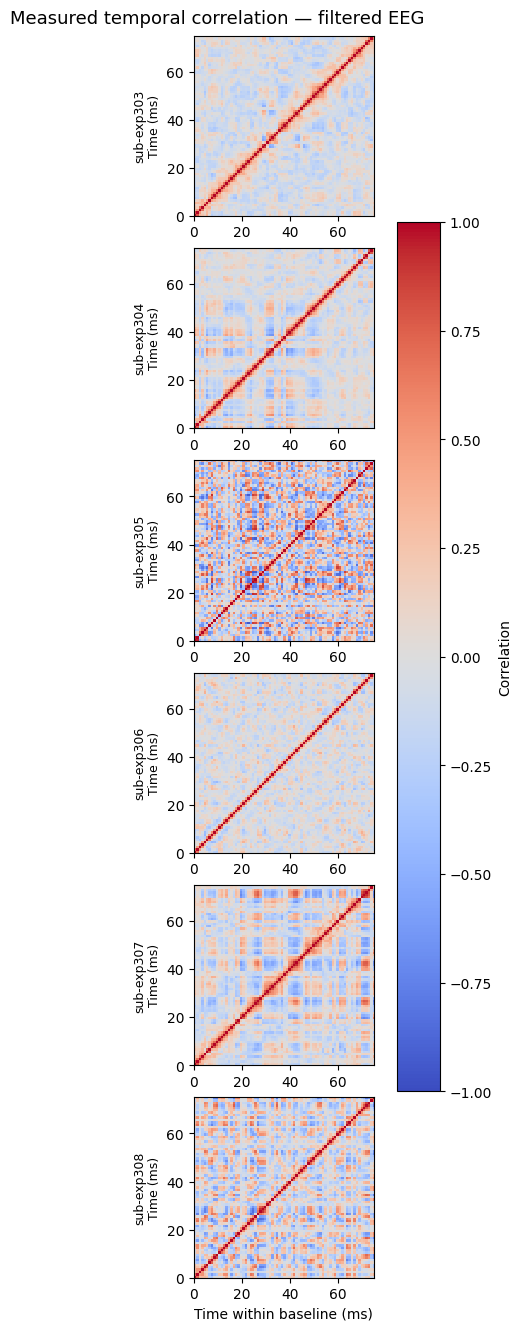

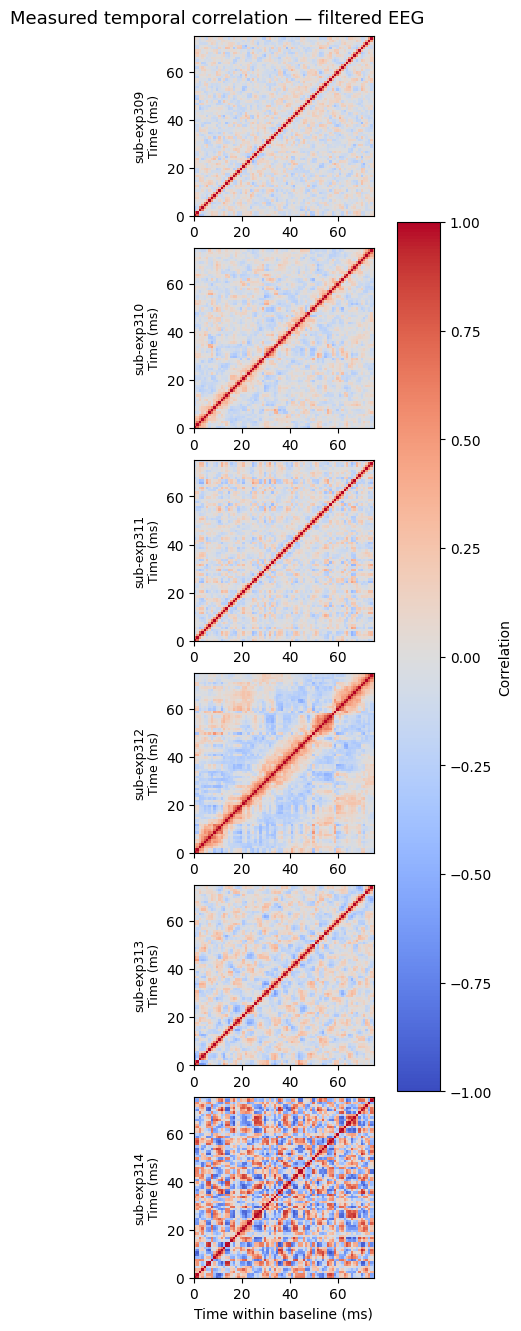

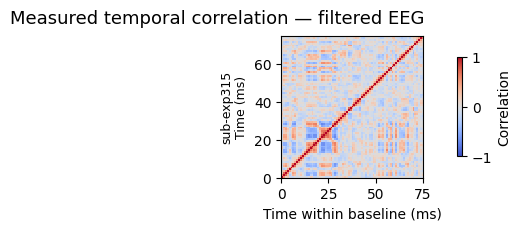

In [12]:
items = list(matrices.items())
PER_PAGE = 6
for page_start in range(0, len(items), PER_PAGE):
    page = items[page_start:page_start + PER_PAGE]
    n = len(page)
    fig, axes = plt.subplots(n, 1, figsize=(6, 2.2 * n), squeeze=False,
                             constrained_layout=True)
    for row, (participant, matrix) in enumerate(page):
        ax = axes[row, 0]
        image = ax.imshow(matrix, origin="lower", cmap="coolwarm", vmin=-1, vmax=1,
                          extent=(0, COVARIANCE_MS, 0, COVARIANCE_MS),
                          interpolation="nearest", aspect="equal")
        ax.set_ylabel(participant + "\nTime (ms)", fontsize=9)
    axes[-1, 0].set_xlabel("Time within baseline (ms)")
    fig.colorbar(image, ax=axes[:, 0], label="Correlation", shrink=0.7)
    fig.suptitle("Measured temporal correlation — filtered EEG", fontsize=13)
    page_number = page_start // PER_PAGE + 1
    fig.savefig(OUTPUT_DIR / f"figure4_measured_correlation_page_{page_number:02d}.png",
                dpi=180, bbox_inches="tight")
    plt.show()

## 7. Are the EEG amplitudes Gaussian?

For participant 221, I use the original unfiltered 10-kHz baseline samples, subtract each window's mean, and draw 20,000 values with a fixed random seed.

The histogram is compared with a normal curve having the same mean and standard deviation. The Q–Q plot is another way to see where the EEG distribution differs from that normal curve, especially in the tails.

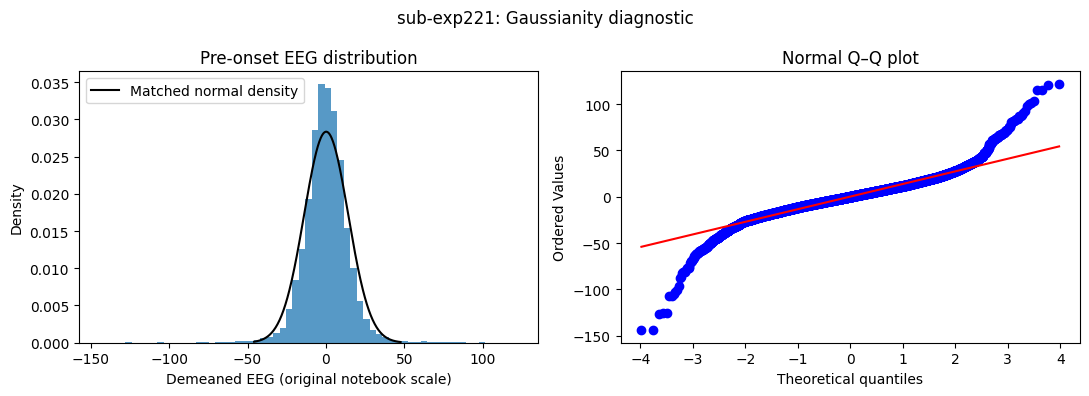

Participant: sub-exp221
Sample size: 20000
Skewness: 0.008
Excess kurtosis: 7.735


In [13]:
if qq_windows is None:
    print(f"No Figure 5: {QQ_PARTICIPANT} was not successfully analyzed in this run.")
else:
    rng = np.random.default_rng(2026)
    values = qq_windows.ravel()
    indices = rng.choice(len(values), size=min(20_000, len(values)), replace=False)
    sample = values[indices]
    mu = sample.mean()
    sd = sample.std(ddof=1)
    asymmetry = float(skew(sample))
    excess = float(kurtosis(sample))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(sample, bins=65, density=True, alpha=0.75)
    limits = np.quantile(sample, [0.005, 0.995])
    xx = np.linspace(*limits, 300)
    axes[0].plot(xx, norm.pdf(xx, loc=mu, scale=sd), color="black",
                 label="Matched normal density")
    axes[0].set(xlabel="Demeaned EEG (original notebook scale)", ylabel="Density",
                title="Pre-onset EEG distribution")
    axes[0].legend()
    probplot(sample, dist="norm", plot=axes[1])
    axes[1].set_title("Normal Q–Q plot")
    fig.suptitle(f"{QQ_PARTICIPANT}: Gaussianity diagnostic")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "figure5_gaussian_qq.png", dpi=180)
    plt.show()

    print(f"Participant: {QQ_PARTICIPANT}")
    print(f"Sample size: {len(sample)}")
    print(f"Skewness: {asymmetry:.3f}")
    print(f"Excess kurtosis: {excess:.3f}")
    pd.DataFrame([{"participant": QQ_PARTICIPANT, "sample_size": len(sample),
                   "skewness": asymmetry, "excess_kurtosis": excess}]).to_csv(
                       OUTPUT_DIR / "figure5_statistics.csv", index=False)

## What I found

The EEG samples remain correlated over short time intervals, even after filtering. The heatmaps also show that the temporal structure is not identical across recordings. For participant 221, the amplitude distribution departs from a normal distribution in the tails.

These results motivate trying a noise model that accounts for temporal dependence. I have not yet tested whether such a model improves the recovered ABR.

A few Notes: The baseline comes before a stimulus but is not guaranteed to contain only noise; participant 223 was excluded from the paper's main analysis because of recording issues; The correlation and distribution-shape results do not depend on that fixed scaling.